In [1]:
import pandas as pd
import numpy as np

In [2]:
rng = np.random.default_rng(42)
n = 300

df = pd.DataFrame({
    'size_m2':          rng.integers(40, 250, n),
    'bedrooms':         rng.integers(1, 6, n),
    'age_years':        rng.integers(0, 50, n),
    'distance_to_center_km': rng.uniform(0.5, 30, n).round(1),
})

# Price (in thousands) = real formula + random noise
df['price'] = (50
               + 2.5 * df['size_m2']
               + 15 * df['bedrooms']
               - 1.2 * df['age_years']
               - 3 * df['distance_to_center_km']
               + rng.normal(0, 25, n)).round(1)

# Add some missing values to practice imputing
df.loc[df.sample(frac=0.08, random_state=1).index, 'age_years'] = np.nan
df.loc[df.sample(frac=0.05, random_state=2).index, 'size_m2'] = np.nan

In [3]:
df.head(10)

,size_m2,bedrooms,age_years,distance_to_center_km,price
0,58.0,2,30.0,1.7,181.5
1,202.0,5,38.0,26.6,532.8
2,177.0,1,36.0,21.4,343.1
3,132.0,5,6.0,5.6,393.6
4,130.0,3,41.0,3.2,338.1
5,220.0,1,26.0,5.9,602.6
6,58.0,2,16.0,29.4,124.7
7,NaN,3,25.0,14.0,507.2
8,82.0,2,48.0,23.6,128.1
9,59.0,1,42.0,19.3,76.2


In [4]:
df.shape

(300, 5)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   size_m2                285 non-null    float64
 1   bedrooms               300 non-null    int64  
 2   age_years              276 non-null    float64
 3   distance_to_center_km  300 non-null    float64
 4   price                  300 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 11.8 KB


In [6]:
df.isna().sum()

,0
size_m2,15
bedrooms,0
age_years,24
distance_to_center_km,0
price,0


In [7]:
X = df.drop(columns=['price'])
y = df['price']

In [8]:
from sklearn.model_selection import train_test_split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

In [12]:
pipe = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    LinearRegression()
)

In [13]:
pipe.fit(X_train, y_train)

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler()),
                ('linearregression', LinearRegression())])

In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = pipe.predict(X_test)

print('MAE :', mean_absolute_error(y_test, y_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R2  :', r2_score(y_test, y_pred))

MAE : 22.139429837961266
RMSE: 31.974776594629663
R2  : 0.9526319338242785


In [15]:
coefs = pipe.named_steps['linearregression'].coef_
pd.Series(coefs, index=X.columns).sort_values()

,0
distance_to_center_km,-24.873997
age_years,-17.177283
bedrooms,23.408996
size_m2,142.498519


In [16]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='r2')
print(scores)
print('Mean R2:', scores.mean())

[0.93806464 0.9290086  0.9609221  0.97264946 0.91252193]
Mean R2: 0.942633346367612


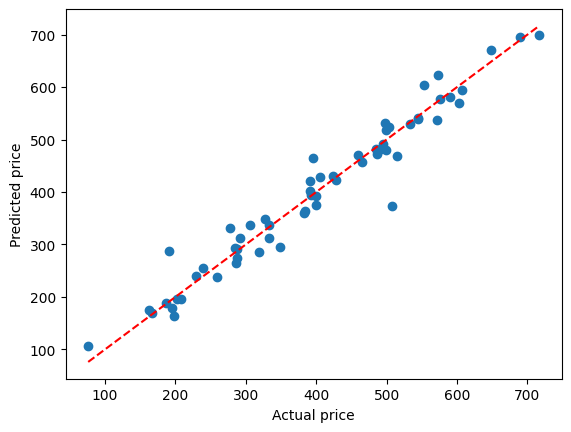

In [17]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual price')
plt.ylabel('Predicted price')
plt.show()